In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

In [16]:
import kagglehub
path = kagglehub.dataset_download("fahmidachowdhury/customer-segmentation-data-for-marketing-analysis")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'customer-segmentation-data-for-marketing-analysis' dataset.
Path to dataset files: /kaggle/input/customer-segmentation-data-for-marketing-analysis


In [15]:
import os
import pandas as pd
print(os.listdir(path))

['customer_segmentation_data.csv']


In [18]:
import glob
import pandas as pd
import os

csv_files = glob.glob(os.path.join(path, "*.csv"))

print("CSV files found:", csv_files)

df = pd.read_csv(csv_files[0])

print(df.head())

print(df.columns.tolist())

print(df.info())

CSV files found: ['/kaggle/input/customer-segmentation-data-for-marketing-analysis/customer_segmentation_data.csv']
   id  age  gender  income  spending_score  membership_years  \
0   1   38  Female   99342              90                 3   
1   2   21  Female   78852              60                 2   
2   3   60  Female  126573              30                 2   
3   4   40   Other   47099              74                 9   
4   5   65  Female  140621              21                 3   

   purchase_frequency preferred_category  last_purchase_amount  
0                  24          Groceries                113.53  
1                  42             Sports                 41.93  
2                  28           Clothing                424.36  
3                   5      Home & Garden                991.93  
4                  25        Electronics                347.08  
['id', 'age', 'gender', 'income', 'spending_score', 'membership_years', 'purchase_frequency', 'preferred_cate

In [17]:
print(df.isnull().sum())
print(df.shape)
print(df.describe())

id                      0
age                     0
gender                  0
income                  0
spending_score          0
membership_years        0
purchase_frequency      0
preferred_category      0
last_purchase_amount    0
KMeans_Cluster          0
DBSCAN_Cluster          0
dtype: int64
(1000, 11)
                id          age         income  spending_score  \
count  1000.000000  1000.000000    1000.000000     1000.000000   
mean    500.500000    43.783000   88500.800000       50.685000   
std     288.819436    15.042213   34230.771122       28.955175   
min       1.000000    18.000000   30004.000000        1.000000   
25%     250.750000    30.000000   57911.750000       26.000000   
50%     500.500000    45.000000   87845.500000       50.000000   
75%     750.250000    57.000000  116110.250000       76.000000   
max    1000.000000    69.000000  149973.000000      100.000000   

       membership_years  purchase_frequency  last_purchase_amount  \
count        1000.00000   

In [6]:
print(df.head())
print(df.columns.tolist())

   id  age  gender  income  spending_score  membership_years  \
0   1   38  Female   99342              90                 3   
1   2   21  Female   78852              60                 2   
2   3   60  Female  126573              30                 2   
3   4   40   Other   47099              74                 9   
4   5   65  Female  140621              21                 3   

   purchase_frequency preferred_category  last_purchase_amount  
0                  24          Groceries                113.53  
1                  42             Sports                 41.93  
2                  28           Clothing                424.36  
3                   5      Home & Garden                991.93  
4                  25        Electronics                347.08  
['id', 'age', 'gender', 'income', 'spending_score', 'membership_years', 'purchase_frequency', 'preferred_category', 'last_purchase_amount']


In [19]:
features = [
    'age',
    'income',
    'spending_score',
    'membership_years',
    'purchase_frequency',
    'last_purchase_amount'
]

X = df[features]

print(X.head())

   age  income  spending_score  membership_years  purchase_frequency  \
0   38   99342              90                 3                  24   
1   21   78852              60                 2                  42   
2   60  126573              30                 2                  28   
3   40   47099              74                 9                   5   
4   65  140621              21                 3                  25   

   last_purchase_amount  
0                113.53  
1                 41.93  
2                424.36  
3                991.93  
4                347.08  


In [20]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled data:")
print(X_scaled[:5])

Scaled data:
[[-0.38464377  0.31686767  1.35846776 -0.86501013 -0.18234781 -1.28154045]
 [-1.51536211 -0.28201608  0.32186512 -1.2153585   1.08200524 -1.52376266]
 [ 1.07863878  1.11277804 -0.71473752 -1.2153585   0.09861954 -0.23000511]
 [-0.25161809 -1.21009592  0.80561302  1.2370801  -1.51694269  1.69007953]
 [ 1.411203    1.52337438 -1.02571832 -0.86501013 -0.11210597 -0.49144272]]


In [9]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

print(df[['id', 'KMeans_Cluster']].head(10))

   id  KMeans_Cluster
0   1               2
1   2               0
2   3               2
3   4               1
4   5               2
5   6               0
6   7               0
7   8               1
8   9               1
9  10               1


In [10]:
dbscan = DBSCAN(
    eps=1.5,
    min_samples=5
)

df['DBSCAN_Cluster'] = dbscan.fit_predict(X_scaled)

print(df[['id', 'DBSCAN_Cluster']].head(10))

print("\nDBSCAN cluster counts:")
print(df['DBSCAN_Cluster'].value_counts().sort_index())

   id  DBSCAN_Cluster
0   1               0
1   2               0
2   3               0
3   4               0
4   5               0
5   6               0
6   7               0
7   8               0
8   9               0
9  10               0

DBSCAN cluster counts:
DBSCAN_Cluster
-1      2
 0    998
Name: count, dtype: int64


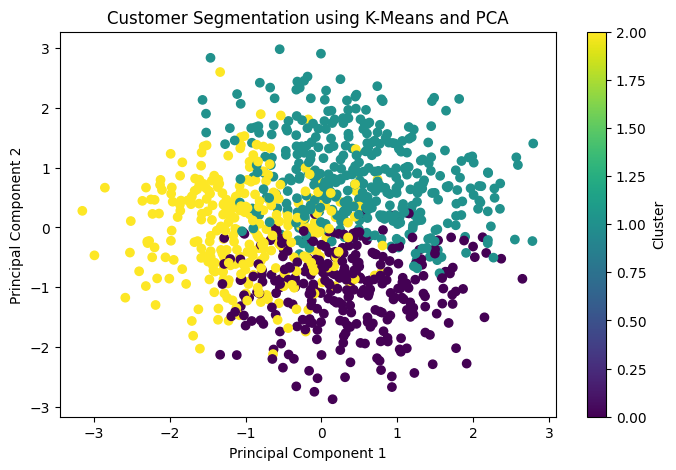

Explained variance ratio: [0.18156391 0.18006055]
Total variance explained: 0.36162446110278545


In [11]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df['KMeans_Cluster']
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('Customer Segmentation using K-Means and PCA')
plt.colorbar(label='Cluster')
plt.show()

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance explained:", pca.explained_variance_ratio_.sum())

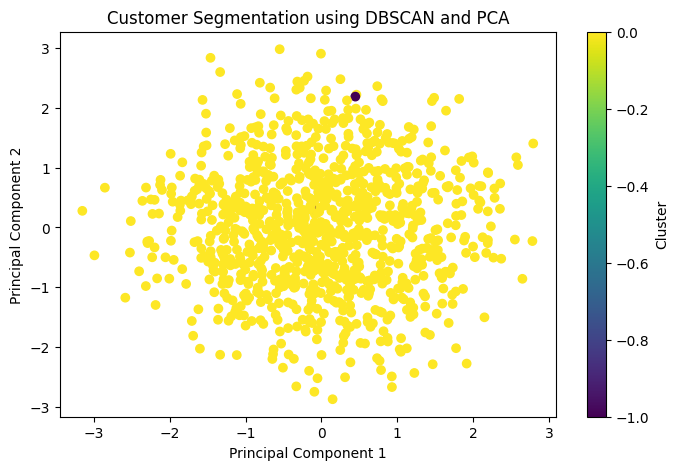

In [12]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df['DBSCAN_Cluster']
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('Customer Segmentation using DBSCAN and PCA')
plt.colorbar(label='Cluster')
plt.show()

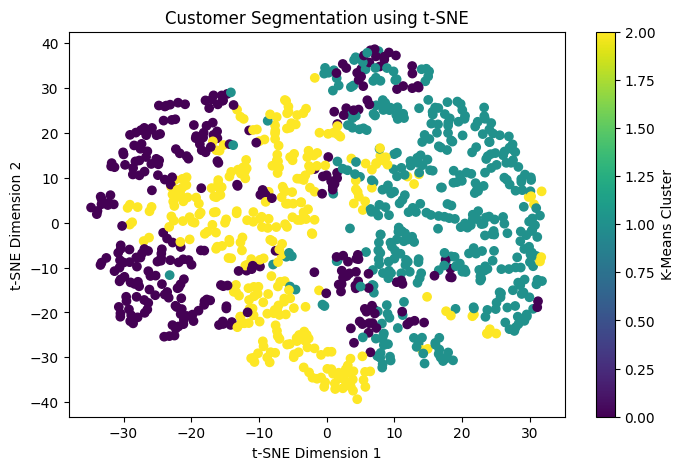

In [13]:
tsne = TSNE(
    n_components=2,
    random_state=42,
    init='pca',
    learning_rate='auto',
    perplexity=30
)

X_tsne = tsne.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))

plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=df['KMeans_Cluster']
)

plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.title('Customer Segmentation using t-SNE')
plt.colorbar(label='K-Means Cluster')
plt.show()

In [14]:
cluster_summary = df.groupby('KMeans_Cluster')[
    features
].mean().round(2)

print(cluster_summary)

                  age    income  spending_score  membership_years  \
KMeans_Cluster                                                      
0               35.87  92064.36           47.38              6.28   
1               48.92  80288.49           49.96              5.58   
2               44.93  95161.92           54.66              4.57   

                purchase_frequency  last_purchase_amount  
KMeans_Cluster                                            
0                            38.13                317.96  
1                            28.44                773.70  
2                            13.54                313.14  
